In [1]:
!pip install -q torch torchvision matplotlib pillow torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 26.0 MB/s eta 0:00:00


In [2]:
!pip install lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 2.7 MB/s eta 0:00:00


In [3]:
import os
import random
import zipfile
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms
from torch.utils.data import DataLoader

from google.colab import files

from torchmetrics.image import PeakSignalNoiseRatio
from torchmetrics.image import StructuralSimilarityIndexMeasure


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)


Device: cuda


## Konfigurasyon



In [6]:
IMAGE_SIZE = 64
TAESD_INPUT_SIZE = 512

NUM_ASCII_CLASSES = 256

SAMPLES_PER_CLASS = 4
SAMPLES_PER_EPOCH = NUM_ASCII_CLASSES * SAMPLES_PER_CLASS

# Final protocol
EPOCHS = 75
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
MIN_LR = 1e-5
SEED = 42

DELTA_SCALE = 0.10

CLASS_WEIGHT = 1.0
IMAGE_WEIGHT = 0.1

# Fixed LPIPS coefficient for this run.
# Change only this if you intentionally test another coefficient.
LPIPS_WEIGHT = 10.0

# Validation is NOT run during training.
# After epoch 75, only best_train and final_epoch75 are evaluated.
VAL_MESSAGES_PER_IMAGE = 64
VAL_SEED = 2026

print('Seed:', SEED)
print('LPIPS weight:', LPIPS_WEIGHT)
print('Epochs:', EPOCHS)
print('Validation during training: OFF')


Seed: 42
LPIPS weight: 10.0
Epochs: 75
Validation during training: OFF


## Veri Yukleme

In [7]:
uploaded = files.upload()

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall()

print(os.listdir())


Saving 100_images.zip to 100_images.zip
['.config', '100_images.zip', '__MACOSX', '100_images', 'sample_data']


In [8]:
TRAIN_DIR = "100_images/train"
VAL_DIR = "100_images/val"
TEST_DIR = "100_images/test"

to_tensor_resize = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    transforms.ToTensor()
])


def load_images(folder):
    image_files = []

    for fname in sorted(os.listdir(folder)):
        # Skip macOS hidden / AppleDouble files
        if fname.startswith('.') or fname.startswith('._'):
            continue

        if fname.lower().endswith((
            '.jpg', '.jpeg', '.png', '.webp', '.bmp'
        )):
            image_files.append(os.path.join(folder, fname))

    images = []
    valid_files = []

    for path in image_files:
        try:
            image = Image.open(path).convert('RGB')
        except Exception as e:
            print(f'Skipping unreadable file: {path} | {e}')
            continue

        image = to_tensor_resize(image)
        images.append(image)
        valid_files.append(path)

    if len(images) == 0:
        raise RuntimeError(f'{folder} klasorunde goruntu bulunamadi.')

    return torch.stack(images), valid_files


x_train, train_files = load_images(TRAIN_DIR)
x_val, val_files = load_images(VAL_DIR)
x_test, test_files = load_images(TEST_DIR)

print('Train image count:', len(x_train))
print('Train tensor shape:', x_train.shape)
print('Validation image count:', len(x_val))
print('Validation tensor shape:', x_val.shape)
print('Test image count:', len(x_test))
print('Test tensor shape:', x_test.shape)


Train image count: 100
Train tensor shape: torch.Size([100, 3, 64, 64])
Validation image count: 20
Validation tensor shape: torch.Size([20, 3, 64, 64])
Test image count: 20
Test tensor shape: torch.Size([20, 3, 64, 64])


## TAESD

In [9]:
TAESD_BASE_URL = "https://raw.githubusercontent.com/madebyollin/taesd/main"

TAESD_FILES = [
    "taesd.py",
    "taesd_encoder.pth",
    "taesd_decoder.pth"
]

for fname in TAESD_FILES:

    if not os.path.exists(fname):

        print("Downloading:", fname)

        urllib.request.urlretrieve(f"{TAESD_BASE_URL}/{fname}", fname)

from taesd import TAESD

print("TAESD dosyalari hazir.")


Downloading: taesd.py
Downloading: taesd_encoder.pth
Downloading: taesd_decoder.pth
TAESD dosyalari hazir.


In [10]:
taesd = TAESD(
    encoder_path="taesd_encoder.pth",
    decoder_path="taesd_decoder.pth"
).to(DEVICE)

taesd.eval()

print("TAESD yuklendi.")


TAESD yuklendi.


In [11]:


for parameter in taesd.encoder.parameters():
    parameter.requires_grad_(False)

for parameter in taesd.decoder.parameters():
    parameter.requires_grad_(False)

taesd.eval()

print(
    "Encoder trainable:",
    any(p.requires_grad for p in taesd.encoder.parameters())
)

print(
    "Decoder trainable:",
    any(p.requires_grad for p in taesd.decoder.parameters())
)


Encoder trainable: False
Decoder trainable: False


In [12]:

upsample_512 = transforms.Resize(
    (TAESD_INPUT_SIZE, TAESD_INPUT_SIZE),
    antialias=True
)


downsample_64 = transforms.Resize(
    (IMAGE_SIZE, IMAGE_SIZE),
    antialias=True
)

print(
    f"Pipeline resize: "
    f"{IMAGE_SIZE} -> {TAESD_INPUT_SIZE} -> {IMAGE_SIZE}"
)

Pipeline resize: 64 -> 512 -> 64


In [13]:
with torch.no_grad():

    sample_512 = upsample_512(
        x_train[:1].to(DEVICE)
    )

    sample_latent = taesd.encoder(
        sample_512
    )

LATENT_CHANNELS = sample_latent.shape[1]
LATENT_SIZE = sample_latent.shape[2]


calculating latent_std, max_delta

In [14]:
with torch.no_grad():

    latent_samples = []

    for start in range(0, len(x_train), 8):

        batch_64 = x_train[
            start:start + 8
        ].to(DEVICE)

        batch_512 = upsample_512(
            batch_64
        )

        latent_batch = taesd.encoder(
            batch_512
        )

        latent_samples.append(
            latent_batch
        )

    all_latents = torch.cat(
        latent_samples,
        dim=0
    )

LATENT_STD = all_latents.std().item()

MAX_DELTA = DELTA_SCALE * LATENT_STD

print("Latent std:", LATENT_STD)
print("Maximum delta:", MAX_DELTA)


Latent std: 1.004361629486084
Maximum delta: 0.10043616294860841


In [15]:
def create_epoch_ascii_labels(samples_per_class,device):

    #[0,0,0,0,1,1,1,1,...,255,255,255,255]
    labels = torch.arange(
    NUM_ASCII_CLASSES,
    dtype=torch.long,
    device=device
).repeat_interleave(samples_per_class)

    permutation = torch.randperm(labels.size(0),device=device)

    labels = labels[permutation]

    return labels

In [16]:
from google.colab import drive
drive.mount('/content/drive')

import os

WEIGHT_TAG = str(LPIPS_WEIGHT).replace('.', 'p')
RUN_TAG = f'LPIPS_w{WEIGHT_TAG}_seed{SEED}'

CHECKPOINT_DIR = os.path.join(
    '/content/drive/MyDrive/TAESD_256_Message_FinalProtocol',
    RUN_TAG
)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

LATEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    f'latest_{RUN_TAG}.pth'
)

BEST_TRAIN_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    f'best_train_{RUN_TAG}.pth'
)

FINAL_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    f'final_epoch_{EPOCHS}_{RUN_TAG}.pth'
)

SELECTED_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    f'selected_by_val_{RUN_TAG}.pth'
)

print('Run:', RUN_TAG)
print('Checkpoint directory:', CHECKPOINT_DIR)
print('Latest checkpoint:', LATEST_CHECKPOINT_PATH)
print('Best-train checkpoint:', BEST_TRAIN_CHECKPOINT_PATH)
print('Final checkpoint:', FINAL_CHECKPOINT_PATH)
print('Selected-by-validation checkpoint:', SELECTED_CHECKPOINT_PATH)


Mounted at /content/drive
Run: LPIPS_w10p0_seed42
Checkpoint directory: /content/drive/MyDrive/TAESD_256_Message_FinalProtocol/LPIPS_w10p0_seed42
Latest checkpoint: /content/drive/MyDrive/TAESD_256_Message_FinalProtocol/LPIPS_w10p0_seed42/latest_LPIPS_w10p0_seed42.pth
Best-train checkpoint: /content/drive/MyDrive/TAESD_256_Message_FinalProtocol/LPIPS_w10p0_seed42/best_train_LPIPS_w10p0_seed42.pth
Final checkpoint: /content/drive/MyDrive/TAESD_256_Message_FinalProtocol/LPIPS_w10p0_seed42/final_epoch_75_LPIPS_w10p0_seed42.pth
Selected-by-validation checkpoint: /content/drive/MyDrive/TAESD_256_Message_FinalProtocol/LPIPS_w10p0_seed42/selected_by_val_LPIPS_w10p0_seed42.pth


##  Modeller



In [17]:
class LatentEmbedder(nn.Module):

    def __init__(self,num_classes,latent_channels,latent_size,max_delta):

        super().__init__()

        self.latent_channels = latent_channels
        self.latent_size = latent_size
        self.max_delta = max_delta

        # message class -> vector with 128 dim
        self.message_embedding = nn.Embedding(num_embeddings=num_classes,embedding_dim=128)

        # message -> 8x8
        self.message_projection = nn.Sequential(
            nn.Linear(128,256 * 8 * 8),nn.ReLU()
        )

        # 8x8x256 -> 32x64x64
        self.message_upsampler = nn.Sequential(
            nn.ConvTranspose2d(256,128,kernel_size=4,stride=2,padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128,64,kernel_size=4,stride=2,padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64,32,kernel_size=4,stride=2,padding=1),
            nn.ReLU()
        )


        # 36x64x64 -> 4x64x64
        self.delta_network = nn.Sequential(
            nn.Conv2d(latent_channels + 32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.Conv2d(64,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.Conv2d(32,latent_channels,kernel_size=3,padding=1)
        )

    def forward(self,latent_clean,message_labels):

        batch_size = latent_clean.size(0)
        # message -> 128D vector
        message_vector = self.message_embedding(message_labels)
        # project and reshape the vector into a 256x8x8 feature map
        message_map = self.message_projection(message_vector)

        message_map = message_map.view(batch_size,256,8,8)
        # 8x8x256 -> 32x64x64
        message_map = self.message_upsampler(message_map)

        combined_input = torch.cat([latent_clean,message_map],dim=1)

        raw_delta = self.delta_network(combined_input)

        delta = torch.tanh(raw_delta) * self.max_delta
        # message embedding
        latent_embedded = (latent_clean + delta)

        return latent_embedded, delta

In [18]:
class MessageExtractor(nn.Module):

    def __init__(self,num_classes=256):

        super().__init__()

        # 3x64x64 (rgb photo) -> 1x1x256
        self.features = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(4,32),
            nn.ReLU(),
            nn.Conv2d(32,64,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(8,64),
            nn.ReLU(),
            nn.Conv2d(64,128,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(8,128),
            nn.ReLU(),
            nn.Conv2d(128,256,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(16,256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.output_layer = nn.Linear(256,num_classes)

    def forward(self,image_64):

        features = self.features(image_64)

        features = features.flatten(start_dim=1)

        logits = self.output_layer(features)

        return logits

In [19]:
latent_embedder = LatentEmbedder(
    num_classes=NUM_ASCII_CLASSES,
    latent_channels=LATENT_CHANNELS,
    latent_size=LATENT_SIZE,
    max_delta=MAX_DELTA
).to(DEVICE)

message_extractor = MessageExtractor(
    num_classes=NUM_ASCII_CLASSES
).to(DEVICE)



In [20]:
import random
import numpy as np
import torch.optim as optim

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

optimizer = optim.AdamW(
    list(latent_embedder.parameters())
    + list(message_extractor.parameters()),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=MIN_LR
)

class_loss_fn = nn.CrossEntropyLoss()
image_loss_fn = nn.MSELoss()

import lpips
lpips_loss_fn = lpips.LPIPS(net='alex').to(DEVICE)
lpips_loss_fn.eval()
for param in lpips_loss_fn.parameters():
    param.requires_grad = False

print('Optimizer: AdamW')
print('Initial learning rate:', LEARNING_RATE)
print('Scheduler: CosineAnnealingLR')
print('LPIPS weight:', LPIPS_WEIGHT)


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 189MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
Optimizer: AdamW
Initial learning rate: 0.001
Scheduler: CosineAnnealingLR
LPIPS weight: 10.0


In [21]:
history = {
    'total_loss': [],
    'class_loss': [],
    'image_loss': [],
    'lpips_loss': [],
    'accuracy': [],
    'delta_mean': [],
    'delta_max': [],
    'learning_rate': []
}

START_EPOCH = 0

# Best TRAIN checkpoint:
# primary = highest training message accuracy
# tie-break = lower training LPIPS
best_train_accuracy = -1.0
best_train_lpips = float('inf')
best_train_epoch = 0

# Fixed validation pairs.
# The same random validation messages are reused for every run.
val_gen = torch.Generator().manual_seed(VAL_SEED)
fixed_val_images = []
fixed_val_labels = []

for image_idx in range(len(x_val)):
    labels = torch.randperm(
        NUM_ASCII_CLASSES,
        generator=val_gen
    )[:VAL_MESSAGES_PER_IMAGE]

    fixed_val_images.append(
        x_val[image_idx:image_idx+1].repeat(
            VAL_MESSAGES_PER_IMAGE, 1, 1, 1
        )
    )
    fixed_val_labels.append(labels)

fixed_val_images = torch.cat(fixed_val_images, dim=0)
fixed_val_labels = torch.cat(fixed_val_labels, dim=0)

print('Training state initialized.')
print('Fixed validation pairs:', len(fixed_val_labels))


Training state initialized.
Fixed validation pairs: 1280


In [22]:
import os
import torch

# Keep False for a fresh run.
# Set True only if this exact weight/seed run was interrupted.
RESUME_TRAINING = False

if RESUME_TRAINING and os.path.exists(LATEST_CHECKPOINT_PATH):
    checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location=DEVICE
    )

    latent_embedder.load_state_dict(
        checkpoint['latent_embedder_state_dict']
    )
    message_extractor.load_state_dict(
        checkpoint['message_extractor_state_dict']
    )
    optimizer.load_state_dict(
        checkpoint['optimizer_state_dict']
    )
    scheduler.load_state_dict(
        checkpoint['scheduler_state_dict']
    )

    START_EPOCH = checkpoint['epoch']
    history = checkpoint.get('history', history)

    best_train_accuracy = checkpoint.get(
        'best_train_accuracy',
        best_train_accuracy
    )
    best_train_lpips = checkpoint.get(
        'best_train_lpips',
        best_train_lpips
    )
    best_train_epoch = checkpoint.get(
        'best_train_epoch',
        best_train_epoch
    )

    print('Checkpoint loaded.')
    print('Training will resume from epoch:', START_EPOCH)
    print('Best train epoch so far:', best_train_epoch)
    print(
        'Best train accuracy so far:',
        f'{best_train_accuracy * 100:.2f}%'
    )
else:
    START_EPOCH = 0
    print('Fresh run. Starting from epoch 0.')


Fresh run. Starting from epoch 0.


In [23]:
from torch.utils.data import DataLoader, TensorDataset

for epoch in range(START_EPOCH, EPOCHS):

    latent_embedder.train()
    message_extractor.train()
    taesd.eval()

    epoch_message_labels = create_epoch_ascii_labels(
        samples_per_class=SAMPLES_PER_CLASS,
        device=torch.device('cpu')
    )

    epoch_image_indices = torch.randint(
        low=0,
        high=len(x_train),
        size=(SAMPLES_PER_EPOCH,),
        dtype=torch.long
    )

    epoch_images = x_train[epoch_image_indices]

    epoch_dataset = TensorDataset(
        epoch_images,
        epoch_message_labels
    )

    epoch_loader = DataLoader(
        epoch_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    running_total_loss = 0.0
    running_class_loss = 0.0
    running_image_loss = 0.0
    running_lpips_loss = 0.0
    running_correct = 0
    running_samples = 0
    running_delta_mean = 0.0
    running_delta_max = 0.0
    batch_count = 0

    for batch_64, message_labels in epoch_loader:

        batch_64 = batch_64.to(DEVICE)
        message_labels = message_labels.to(DEVICE)

        batch_512 = upsample_512(batch_64)

        with torch.no_grad():
            latent_clean = taesd.encoder(batch_512)
            clean_recon_512 = taesd.decoder(
                latent_clean
            ).clamp(0, 1)
            clean_recon_64 = downsample_64(
                clean_recon_512
            )

        latent_embedded, delta = latent_embedder(
            latent_clean,
            message_labels
        )

        stego_512 = taesd.decoder(
            latent_embedded
        ).clamp(0, 1)

        stego_64 = downsample_64(
            stego_512
        )

        logits = message_extractor(
            stego_64
        )

        class_loss = class_loss_fn(
            logits,
            message_labels
        )

        image_loss = image_loss_fn(
            stego_64,
            clean_recon_64
        )

        lpips_loss = lpips_loss_fn(
            stego_64 * 2 - 1,
            clean_recon_64 * 2 - 1
        ).mean()

        total_loss = (
            CLASS_WEIGHT * class_loss
            + IMAGE_WEIGHT * image_loss
            + LPIPS_WEIGHT * lpips_loss
        )

        optimizer.zero_grad()
        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            list(latent_embedder.parameters())
            + list(message_extractor.parameters()),
            max_norm=5.0
        )

        optimizer.step()

        with torch.no_grad():
            predicted_labels = logits.argmax(dim=1)
            correct = (
                predicted_labels == message_labels
            ).sum().item()

        running_total_loss += total_loss.item()
        running_class_loss += class_loss.item()
        running_image_loss += image_loss.item()
        running_lpips_loss += lpips_loss.item()
        running_correct += correct
        running_samples += message_labels.size(0)
        running_delta_mean += delta.abs().mean().item()
        running_delta_max = max(
            running_delta_max,
            delta.abs().max().item()
        )
        batch_count += 1

    average_total_loss = running_total_loss / batch_count
    average_class_loss = running_class_loss / batch_count
    average_image_loss = running_image_loss / batch_count
    average_lpips_loss = running_lpips_loss / batch_count
    average_accuracy = running_correct / running_samples
    average_delta_mean = running_delta_mean / batch_count

    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    history['total_loss'].append(average_total_loss)
    history['class_loss'].append(average_class_loss)
    history['image_loss'].append(average_image_loss)
    history['lpips_loss'].append(average_lpips_loss)
    history['accuracy'].append(average_accuracy)
    history['delta_mean'].append(average_delta_mean)
    history['delta_max'].append(running_delta_max)
    history['learning_rate'].append(current_lr)

    current_epoch = epoch + 1

    # Best TRAIN checkpoint:
    # highest train accuracy; tie -> lower LPIPS.
    is_best_train = (
        average_accuracy > best_train_accuracy
        or (
            abs(average_accuracy - best_train_accuracy) < 1e-12
            and average_lpips_loss < best_train_lpips
        )
    )

    if is_best_train:
        best_train_accuracy = average_accuracy
        best_train_lpips = average_lpips_loss
        best_train_epoch = current_epoch

    checkpoint_data = {
        'latent_embedder_state_dict':
            latent_embedder.state_dict(),
        'message_extractor_state_dict':
            message_extractor.state_dict(),
        'optimizer_state_dict':
            optimizer.state_dict(),
        'scheduler_state_dict':
            scheduler.state_dict(),
        'epoch':
            current_epoch,
        'accuracy':
            average_accuracy,
        'class_loss':
            average_class_loss,
        'image_loss':
            average_image_loss,
        'lpips_loss':
            average_lpips_loss,
        'total_loss':
            average_total_loss,
        'delta_mean':
            average_delta_mean,
        'delta_max':
            running_delta_max,
        'learning_rate':
            current_lr,
        'history':
            history,
        'num_classes':
            NUM_ASCII_CLASSES,
        'samples_per_class':
            SAMPLES_PER_CLASS,
        'lpips_weight':
            LPIPS_WEIGHT,
        'seed':
            SEED,
        'best_train_accuracy':
            best_train_accuracy,
        'best_train_lpips':
            best_train_lpips,
        'best_train_epoch':
            best_train_epoch
    }

    # Recovery checkpoint: overwritten every epoch.
    torch.save(
        checkpoint_data,
        LATEST_CHECKPOINT_PATH
    )

    # Candidate 1: best training checkpoint.
    if is_best_train:
        torch.save(
            checkpoint_data,
            BEST_TRAIN_CHECKPOINT_PATH
        )

    # Optional recovery snapshots every 5 epochs.
    if current_epoch % 5 == 0:
        periodic_path = os.path.join(
            CHECKPOINT_DIR,
            f'{RUN_TAG}_epoch_{current_epoch:03d}.pth'
        )
        torch.save(
            checkpoint_data,
            periodic_path
        )

    # Candidate 2: final epoch checkpoint.
    if current_epoch == EPOCHS:
        torch.save(
            checkpoint_data,
            FINAL_CHECKPOINT_PATH
        )

    msg = (
        f'Epoch {current_epoch:03d}/{EPOCHS} | '
        f'Total: {average_total_loss:.6f} | '
        f'Class: {average_class_loss:.6f} | '
        f'Image: {average_image_loss:.8f} | '
        f'Train Acc: {average_accuracy * 100:6.2f}% | '
        f'LPIPS: {average_lpips_loss:.6f} | '
        f'Delta Mean: {average_delta_mean:.6f} | '
        f'Delta Max: {running_delta_max:.6f} | '
        f'LR: {current_lr:.2e}'
    )

    if is_best_train:
        msg += ' | NEW BEST TRAIN'

    print(msg)

print('\nTraining completed.')
print(
    'Best train checkpoint:',
    BEST_TRAIN_CHECKPOINT_PATH
)
print(
    'Best train epoch:',
    best_train_epoch
)
print(
    'Best train accuracy:',
    f'{best_train_accuracy * 100:.2f}%'
)
print(
    'Best train LPIPS:',
    f'{best_train_lpips:.6f}'
)
print(
    'Final checkpoint:',
    FINAL_CHECKPOINT_PATH
)


Epoch 001/75 | Total: 5.791171 | Class: 5.790861 | Image: 0.00000755 | Train Acc:   0.00% | LPIPS: 0.000031 | Delta Mean: 0.004742 | Delta Max: 0.079202 | LR: 1.00e-03 | NEW BEST TRAIN
Epoch 002/75 | Total: 5.624025 | Class: 5.623810 | Image: 0.00000592 | Train Acc:   0.20% | LPIPS: 0.000021 | Delta Mean: 0.003930 | Delta Max: 0.092953 | LR: 9.98e-04 | NEW BEST TRAIN
Epoch 003/75 | Total: 5.614858 | Class: 5.614664 | Image: 0.00000503 | Train Acc:   0.00% | LPIPS: 0.000019 | Delta Mean: 0.003726 | Delta Max: 0.089073 | LR: 9.96e-04
Epoch 004/75 | Total: 5.598347 | Class: 5.598209 | Image: 0.00000339 | Train Acc:   0.10% | LPIPS: 0.000014 | Delta Mean: 0.003034 | Delta Max: 0.080333 | LR: 9.93e-04
Epoch 005/75 | Total: 5.595141 | Class: 5.594872 | Image: 0.00000658 | Train Acc:   0.10% | LPIPS: 0.000027 | Delta Mean: 0.004576 | Delta Max: 0.097006 | LR: 9.89e-04
Epoch 006/75 | Total: 5.591469 | Class: 5.591379 | Image: 0.00000353 | Train Acc:   0.29% | LPIPS: 0.000009 | Delta Mean: 0.00

In [24]:
import os
import copy
import torch
from torch.utils.data import DataLoader, TensorDataset


def evaluate_checkpoint_on_validation(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

    latent_embedder.load_state_dict(
        checkpoint['latent_embedder_state_dict']
    )
    message_extractor.load_state_dict(
        checkpoint['message_extractor_state_dict']
    )

    latent_embedder.eval()
    message_extractor.eval()
    taesd.eval()

    val_dataset = TensorDataset(
        fixed_val_images,
        fixed_val_labels
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )

    running_ce = 0.0
    running_lpips = 0.0
    running_correct = 0
    running_samples = 0

    with torch.no_grad():

        for batch_64, labels in val_loader:

            batch_64 = batch_64.to(DEVICE)
            labels = labels.to(DEVICE)

            batch_512 = upsample_512(
                batch_64
            )

            latent_clean = taesd.encoder(
                batch_512
            )

            clean_recon_512 = taesd.decoder(
                latent_clean
            ).clamp(0, 1)

            clean_recon_64 = downsample_64(
                clean_recon_512
            )

            latent_embedded, _ = latent_embedder(
                latent_clean,
                labels
            )

            stego_512 = taesd.decoder(
                latent_embedded
            ).clamp(0, 1)

            stego_64 = downsample_64(
                stego_512
            )

            logits = message_extractor(
                stego_64
            )

            ce = class_loss_fn(
                logits,
                labels
            )

            lp = lpips_loss_fn(
                stego_64 * 2 - 1,
                clean_recon_64 * 2 - 1
            ).mean()

            bs = labels.size(0)

            running_ce += ce.item() * bs
            running_lpips += lp.item() * bs
            running_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            running_samples += bs

    return {
        'checkpoint_path':
            checkpoint_path,
        'epoch':
            checkpoint['epoch'],
        'accuracy':
            running_correct / running_samples,
        'class_loss':
            running_ce / running_samples,
        'lpips_loss':
            running_lpips / running_samples
    }


candidate_paths = [
    BEST_TRAIN_CHECKPOINT_PATH,
    FINAL_CHECKPOINT_PATH
]

for path in candidate_paths:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f'Candidate checkpoint not found: {path}'
        )

validation_results = [
    evaluate_checkpoint_on_validation(path)
    for path in candidate_paths
]

print('\n===== VALIDATION COMPARISON =====')

for result in validation_results:
    print(
        f"Epoch {result['epoch']:03d} | "
        f"Val Acc: {result['accuracy'] * 100:.2f}% | "
        f"Val CE: {result['class_loss']:.6f} | "
        f"Val LPIPS: {result['lpips_loss']:.6f}"
    )

# Selection rule:
# 1) higher validation message accuracy
# 2) tie -> lower validation LPIPS
selected = validation_results[0]

for result in validation_results[1:]:
    better = (
        result['accuracy'] > selected['accuracy']
        or (
            abs(
                result['accuracy']
                - selected['accuracy']
            ) < 1e-12
            and result['lpips_loss']
            < selected['lpips_loss']
        )
    )

    if better:
        selected = result

selected_checkpoint = torch.load(
    selected['checkpoint_path'],
    map_location=DEVICE
)

selected_checkpoint[
    'selection_validation_metrics'
] = {
    'accuracy':
        selected['accuracy'],
    'class_loss':
        selected['class_loss'],
    'lpips_loss':
        selected['lpips_loss']
}

selected_checkpoint[
    'selection_candidates'
] = validation_results

torch.save(
    selected_checkpoint,
    SELECTED_CHECKPOINT_PATH
)

print('\n===== SELECTED MODEL =====')
print('Selected epoch:', selected['epoch'])
print(
    'Validation accuracy:',
    f"{selected['accuracy'] * 100:.2f}%"
)
print(
    'Validation LPIPS:',
    f"{selected['lpips_loss']:.6f}"
)
print(
    'Saved to:',
    SELECTED_CHECKPOINT_PATH
)

# Load selected model for the following cells.
latent_embedder.load_state_dict(
    selected_checkpoint[
        'latent_embedder_state_dict'
    ]
)

message_extractor.load_state_dict(
    selected_checkpoint[
        'message_extractor_state_dict'
    ]
)

latent_embedder.eval()
message_extractor.eval()
taesd.eval()



===== VALIDATION COMPARISON =====
Epoch 074 | Val Acc: 89.22% | Val CE: 1.124413 | Val LPIPS: 0.002183
Epoch 075 | Val Acc: 89.38% | Val CE: 1.122442 | Val LPIPS: 0.002183

===== SELECTED MODEL =====
Selected epoch: 75
Validation accuracy: 89.38%
Validation LPIPS: 0.002183
Saved to: /content/drive/MyDrive/TAESD_256_Message_FinalProtocol/LPIPS_w10p0_seed42/selected_by_val_LPIPS_w10p0_seed42.pth


TAESD(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Block(
      (conv): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (skip): Identity()
      (fuse): ReLU()
    )
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (3): Block(
      (conv): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (skip): Identity()
      (fuse): ReLU()
    )
    (4): Block(
      (conv): Sequential(
       


256-CLASS LATENT STEGANOGRAPHY RESULTS
Selected checkpoint epoch     : 75
Training accuracy       : 99.41%
Unseen test images      : 20
Message classes         : 256
Total test pairs        : 5120
Correct predictions     : 4600/5120
Overall test accuracy   : 89.84%
Mean test CE loss       : 1.1037

Image change caused by message embedding
PSNR                    : 39.43 dB
SSIM                    : 0.9867


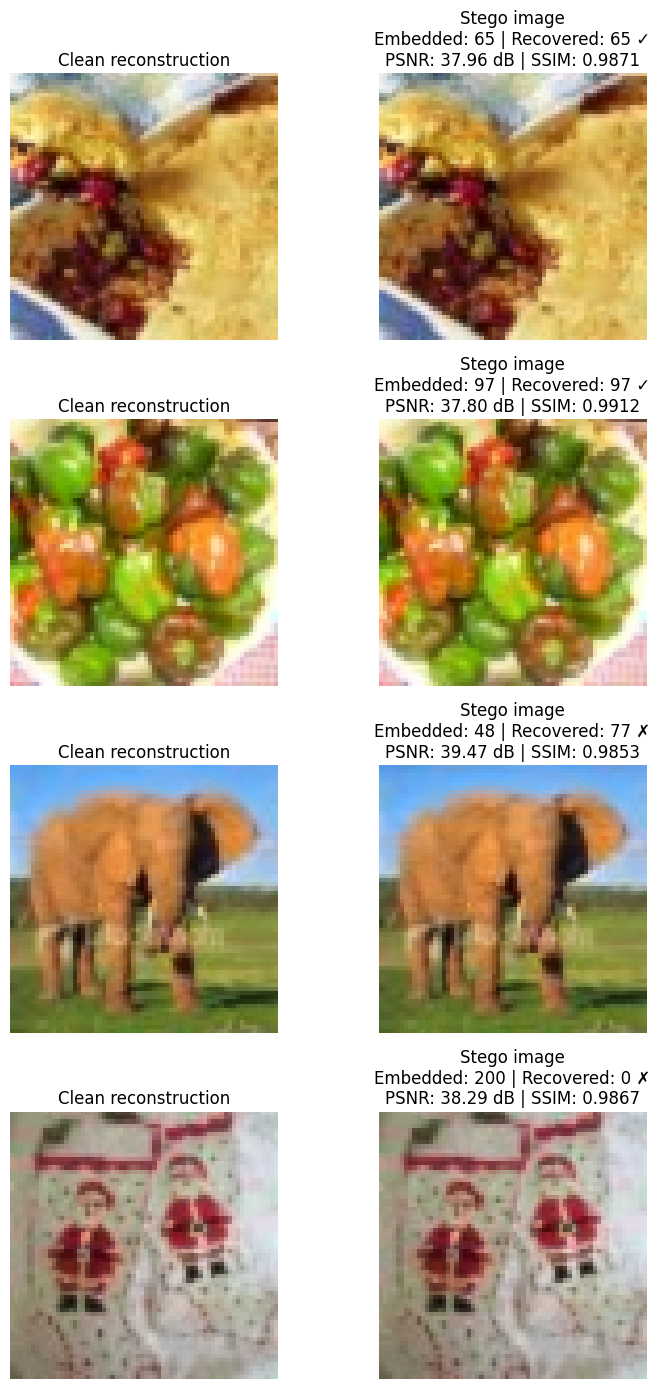

In [25]:
import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchmetrics.functional.image import (
    peak_signal_noise_ratio,
    structural_similarity_index_measure
)



CHECKPOINT_PATH = SELECTED_CHECKPOINT_PATH

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

latent_embedder.load_state_dict(
    checkpoint["latent_embedder_state_dict"]
)

message_extractor.load_state_dict(
    checkpoint["message_extractor_state_dict"]
)

latent_embedder.eval()
message_extractor.eval()
taesd.eval()


#test settings

NUM_TEST_IMAGES = len(x_test)
NUM_CLASSES = 256
MESSAGE_BATCH_SIZE = 32

all_message_labels = torch.arange(
    NUM_CLASSES,
    dtype=torch.long,
    device=DEVICE
)



total_correct = 0
total_predictions = 0

test_losses = []

psnr_scores = []
ssim_scores = []

per_image_accuracies = []


# Four examples for visualization
example_image_indices = [
    0,
    min(1, NUM_TEST_IMAGES - 1),
    min(2, NUM_TEST_IMAGES - 1),
    min(3, NUM_TEST_IMAGES - 1)
]

example_message_labels = [
    65,   # A
    97,   # a
    48,   # 0
    200
]

visual_examples = []


#full test

with torch.no_grad():

    for image_index in range(NUM_TEST_IMAGES):

        original_64_single = x_test[
            image_index:image_index + 1
        ].to(DEVICE)

        original_512_single = upsample_512(
            original_64_single
        )

        latent_clean_single = taesd.encoder(
            original_512_single
        )

        clean_recon_512_single = taesd.decoder(
            latent_clean_single
        ).clamp(0, 1)

        clean_recon_64_single = downsample_64(
            clean_recon_512_single
        )

        image_correct = 0

        for start_index in range(
            0,
            NUM_CLASSES,
            MESSAGE_BATCH_SIZE
        ):

            end_index = min(
                start_index + MESSAGE_BATCH_SIZE,
                NUM_CLASSES
            )

            message_labels = all_message_labels[
                start_index:end_index
            ]

            current_batch_size = (
                message_labels.size(0)
            )

            latent_clean = latent_clean_single.repeat(
                current_batch_size,
                1,
                1,
                1
            )

            clean_recon_64 = clean_recon_64_single.repeat(
                current_batch_size,
                1,
                1,
                1
            )

            latent_embedded, _ = latent_embedder(
                latent_clean,
                message_labels
            )

            stego_512 = taesd.decoder(
                latent_embedded
            ).clamp(0, 1)

            stego_64 = downsample_64(
                stego_512
            )

            logits = message_extractor(
                stego_64
            )

            predicted_labels = logits.argmax(
                dim=1
            )

            batch_loss = F.cross_entropy(
                logits,
                message_labels
            )

            test_losses.append(
                batch_loss.item()
            )

            batch_correct = (
                predicted_labels
                == message_labels
            ).sum().item()

            image_correct += batch_correct
            total_correct += batch_correct
            total_predictions += current_batch_size

            for sample_index in range(
                current_batch_size
            ):

                sample_stego = stego_64[
                    sample_index:
                    sample_index + 1
                ]

                sample_clean = clean_recon_64[
                    sample_index:
                    sample_index + 1
                ]

                psnr_scores.append(
                    peak_signal_noise_ratio(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

                ssim_scores.append(
                    structural_similarity_index_measure(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

        image_accuracy = (
            image_correct / NUM_CLASSES
        )

        per_image_accuracies.append(
            image_accuracy
        )



# prepare visual examples


with torch.no_grad():

    for image_index, message_value in zip(
        example_image_indices,
        example_message_labels
    ):

        original_64 = x_test[
            image_index:image_index + 1
        ].to(DEVICE)

        original_512 = upsample_512(
            original_64
        )

        latent_clean = taesd.encoder(
            original_512
        )

        clean_recon_512 = taesd.decoder(
            latent_clean
        ).clamp(0, 1)

        clean_recon_64 = downsample_64(
            clean_recon_512
        )

        message_label = torch.tensor(
            [message_value],
            dtype=torch.long,
            device=DEVICE
        )

        latent_embedded, _ = latent_embedder(
            latent_clean,
            message_label
        )

        stego_512 = taesd.decoder(
            latent_embedded
        ).clamp(0, 1)

        stego_64 = downsample_64(
            stego_512
        )

        logits = message_extractor(
            stego_64
        )

        recovered_label = logits.argmax(
            dim=1
        ).item()

        example_psnr = peak_signal_noise_ratio(
            stego_64,
            clean_recon_64,
            data_range=1.0
        ).item()

        example_ssim = (
            structural_similarity_index_measure(
                stego_64,
                clean_recon_64,
                data_range=1.0
            ).item()
        )

        visual_examples.append(
            {
                "clean": clean_recon_64.squeeze(0).cpu(),
                "stego": stego_64.squeeze(0).cpu(),
                "embedded": message_value,
                "recovered": recovered_label,
                "psnr": example_psnr,
                "ssim": example_ssim
            }
        )



overall_accuracy = (
    total_correct / total_predictions
)

print("\n" + "=" * 58)
print("256-CLASS LATENT STEGANOGRAPHY RESULTS")
print("=" * 58)

print(
    f"Selected checkpoint epoch     : "
    f"{checkpoint['epoch']}"
)

print(
    f"Training accuracy       : "
    f"{checkpoint['accuracy'] * 100:.2f}%"
)

print(
    f"Unseen test images      : "
    f"{NUM_TEST_IMAGES}"
)

print(
    f"Message classes         : "
    f"{NUM_CLASSES}"
)

print(
    f"Total test pairs        : "
    f"{total_predictions}"
)

print(
    f"Correct predictions     : "
    f"{total_correct}/{total_predictions}"
)

print(
    f"Overall test accuracy   : "
    f"{overall_accuracy * 100:.2f}%"
)

print(
    f"Mean test CE loss       : "
    f"{np.mean(test_losses):.4f}"
)

print("\nImage change caused by message embedding")

print(
    f"PSNR                    : "
    f"{np.mean(psnr_scores):.2f} dB"
)

print(
    f"SSIM                    : "
    f"{np.mean(ssim_scores):.4f}"
)


# show four examples

fig, axes = plt.subplots(
    4,
    2,
    figsize=(8, 14)
)

for row_index, example in enumerate(
    visual_examples
):

    clean_image = (
        example["clean"]
        .permute(1, 2, 0)
        .numpy()
    )

    stego_image = (
        example["stego"]
        .permute(1, 2, 0)
        .numpy()
    )

    axes[row_index, 0].imshow(
        clean_image
    )

    axes[row_index, 0].set_title(
        "Clean reconstruction"
    )

    axes[row_index, 0].axis(
        "off"
    )

    axes[row_index, 1].imshow(
        stego_image
    )

    is_correct = (
        example["embedded"]
        == example["recovered"]
    )

    result_symbol = (
        "✓" if is_correct else "✗"
    )

    axes[row_index, 1].set_title(
        f"Stego image\n"
        f"Embedded: {example['embedded']} | "
        f"Recovered: {example['recovered']} "
        f"{result_symbol}\n"
        f"PSNR: {example['psnr']:.2f} dB | "
        f"SSIM: {example['ssim']:.4f}"
    )

    axes[row_index, 1].axis(
        "off"
    )

plt.tight_layout()
plt.show()



In [26]:
# =========================================================
# 256-CLASS UNSEEN TEST + 8-BIT QUANTIZATION CHECK
# Each unseen test image is evaluated with all 256 messages.
# Model selection used validation only; test is untouched until here.
# =========================================================

import os
import numpy as np
import torch
import torch.nn.functional as F

from torchmetrics.functional.image import (
    peak_signal_noise_ratio,
    structural_similarity_index_measure
)

# =========================================================
# 1. LOAD BEST-VALIDATION CHECKPOINT
# =========================================================

CHECKPOINT_PATH = SELECTED_CHECKPOINT_PATH

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Selected-by-validation checkpoint not found:"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

latent_embedder.load_state_dict(
    checkpoint['latent_embedder_state_dict']
)
message_extractor.load_state_dict(
    checkpoint['message_extractor_state_dict']
)

latent_embedder.eval()
message_extractor.eval()
taesd.eval()

print('Selected-by-validation checkpoint loaded')
print(f"Epoch             : {checkpoint['epoch']}")
print(f"LPIPS weight      : {checkpoint.get('lpips_weight')}")
print(f"Best val accuracy : {checkpoint.get('best_val_accuracy', 0.0) * 100:.2f}%")

# =========================================================
# 2. TEST SETTINGS
# =========================================================

NUM_TEST_IMAGES = len(x_test)
NUM_CLASSES = 256
MESSAGE_BATCH_SIZE = 32

all_message_labels = torch.arange(
    NUM_CLASSES,
    dtype=torch.long,
    device=DEVICE
)

# =========================================================
# 3. RESULT CONTAINERS
# =========================================================

float_correct = 0
quant_correct = 0
total_predictions = 0

float_test_losses = []
quant_test_losses = []

per_image_float_acc = []
per_image_quant_acc = []

embedding_psnr_scores = []
embedding_ssim_scores = []
end_to_end_psnr_scores = []
end_to_end_ssim_scores = []

# =========================================================
# 4. TEST LOOP
# =========================================================

with torch.no_grad():

    for image_index in range(NUM_TEST_IMAGES):

        original_64_single = x_test[
            image_index:image_index + 1
        ].to(DEVICE)

        original_512_single = upsample_512(
            original_64_single
        )

        latent_clean_single = taesd.encoder(
            original_512_single
        )

        clean_recon_512_single = taesd.decoder(
            latent_clean_single
        ).clamp(0, 1)

        clean_recon_64_single = downsample_64(
            clean_recon_512_single
        )

        image_float_correct = 0
        image_quant_correct = 0

        for start_index in range(0, NUM_CLASSES, MESSAGE_BATCH_SIZE):

            end_index = min(
                start_index + MESSAGE_BATCH_SIZE,
                NUM_CLASSES
            )

            message_labels = all_message_labels[
                start_index:end_index
            ]

            current_batch_size = message_labels.size(0)

            latent_clean = latent_clean_single.repeat(
                current_batch_size, 1, 1, 1
            )
            clean_recon_64 = clean_recon_64_single.repeat(
                current_batch_size, 1, 1, 1
            )
            original_64 = original_64_single.repeat(
                current_batch_size, 1, 1, 1
            )

            latent_embedded, _ = latent_embedder(
                latent_clean,
                message_labels
            )

            stego_512 = taesd.decoder(
                latent_embedded
            ).clamp(0, 1)

            stego_64 = downsample_64(
                stego_512
            ).clamp(0, 1)

            # ---------- FLOAT TEST ----------
            logits_float = message_extractor(stego_64)
            pred_float = logits_float.argmax(dim=1)

            float_loss = F.cross_entropy(
                logits_float,
                message_labels
            )
            float_test_losses.append(float_loss.item())

            batch_float_correct = (
                pred_float == message_labels
            ).sum().item()

            image_float_correct += batch_float_correct
            float_correct += batch_float_correct

            # ---------- 8-BIT QUANTIZED / PNG-EQUIVALENT TEST ----------
            # This simulates saving to an 8-bit PNG and loading it again.
            stego_q = torch.round(stego_64 * 255.0) / 255.0

            logits_quant = message_extractor(stego_q)
            pred_quant = logits_quant.argmax(dim=1)

            quant_loss = F.cross_entropy(
                logits_quant,
                message_labels
            )
            quant_test_losses.append(quant_loss.item())

            batch_quant_correct = (
                pred_quant == message_labels
            ).sum().item()

            image_quant_correct += batch_quant_correct
            quant_correct += batch_quant_correct

            total_predictions += current_batch_size

            # Image quality is measured on the float stego output.
            # Quantization robustness is reported separately via accuracy.
            for sample_index in range(current_batch_size):
                sample_stego = stego_64[
                    sample_index:sample_index + 1
                ]
                sample_clean = clean_recon_64[
                    sample_index:sample_index + 1
                ]
                sample_original = original_64[
                    sample_index:sample_index + 1
                ]

                embedding_psnr_scores.append(
                    peak_signal_noise_ratio(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

                embedding_ssim_scores.append(
                    structural_similarity_index_measure(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

                end_to_end_psnr_scores.append(
                    peak_signal_noise_ratio(
                        sample_stego,
                        sample_original,
                        data_range=1.0
                    ).item()
                )

                end_to_end_ssim_scores.append(
                    structural_similarity_index_measure(
                        sample_stego,
                        sample_original,
                        data_range=1.0
                    ).item()
                )

        image_float_acc = image_float_correct / NUM_CLASSES
        image_quant_acc = image_quant_correct / NUM_CLASSES

        per_image_float_acc.append(image_float_acc)
        per_image_quant_acc.append(image_quant_acc)

        print(
            f"Test image {image_index + 1:02d} | "
            f"Float: {image_float_acc * 100:6.2f}% | "
            f"Quantized: {image_quant_acc * 100:6.2f}%"
        )

# =========================================================
# 5. FINAL SUMMARY
# =========================================================

float_accuracy = float_correct / total_predictions
quant_accuracy = quant_correct / total_predictions
accuracy_drop_pp = (float_accuracy - quant_accuracy) * 100.0


print('256-CLASS UNSEEN TEST + QUANTIZATION SUMMARY')
print('=' * 62)

print(f"Checkpoint epoch        : {checkpoint['epoch']}")
print(f"Unseen test images      : {NUM_TEST_IMAGES}")
print(f"Message classes         : {NUM_CLASSES}")
print(f"Total test pairs        : {total_predictions}")

print('Message recovery')
print(f"Float accuracy          : {float_accuracy * 100:.2f}%")
print(f"8-bit quantized accuracy: {quant_accuracy * 100:.2f}%")
print(f"Quantization drop       : {accuracy_drop_pp:.2f} percentage points")
print(f"Float CE loss           : {np.mean(float_test_losses):.6f}")
print(f"Quantized CE loss       : {np.mean(quant_test_losses):.6f}")

print('Embedding-only image quality')
print(f"PSNR                    : {np.mean(embedding_psnr_scores):.2f} dB")
print(f"SSIM                    : {np.mean(embedding_ssim_scores):.4f}")

print('End-to-end image quality')
print(f"PSNR                    : {np.mean(end_to_end_psnr_scores):.2f} dB")
print(f"SSIM                    : {np.mean(end_to_end_ssim_scores):.4f}")

if accuracy_drop_pp <= 1.0:
    print('Quantization check: PASS (<= 1 percentage-point drop)')
else:
    print('Quantization check: REVIEW (> 1 percentage-point drop)')


Selected-by-validation checkpoint loaded
Epoch             : 75
LPIPS weight      : 10.0
Best val accuracy : 0.00%
Test image 01 | Float:  97.27% | Quantized:  97.66%
Test image 02 | Float:  99.22% | Quantized:  99.22%
Test image 03 | Float:  94.53% | Quantized:  95.31%
Test image 04 | Float:  80.08% | Quantized:  80.86%
Test image 05 | Float:  99.61% | Quantized:  99.61%
Test image 06 | Float:  99.22% | Quantized:  99.22%
Test image 07 | Float:  61.72% | Quantized:  61.33%
Test image 08 | Float:  99.61% | Quantized:  99.61%
Test image 09 | Float:  59.38% | Quantized:  60.16%
Test image 10 | Float:  98.83% | Quantized:  98.83%
Test image 11 | Float:  96.88% | Quantized:  96.88%
Test image 12 | Float:  97.66% | Quantized:  97.66%
Test image 13 | Float:  67.19% | Quantized:  67.19%
Test image 14 | Float:  76.95% | Quantized:  76.56%
Test image 15 | Float:  95.31% | Quantized:  95.31%
Test image 16 | Float:  97.27% | Quantized:  97.27%
Test image 17 | Float:  91.80% | Quantized:  92.19%
T